In [97]:
import json
import math
import tkinter as tk
from tkinter import messagebox, ttk

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from mpl_toolkits.mplot3d import Axes3D

import manim as mn
from manim import *

plt.style.use('style.mplstyle')

In [98]:
config.media_width = "75%"
config.verbosity = "WARNING"
config.background_color = BLUE_A
Text.set_default(color=BLACK, stroke_color=BLACK)
MathTex.set_default(color=BLACK, stroke_color=BLACK)

In [99]:
power = 85
base_attack = 105
defense = 78
level = 50

attack_evs = 0
total_evs = 66

In [100]:
def calc_attack(attack_evs, base_attack, atk_mult=1):
    return math.floor((base_attack + attack_evs + 20) * atk_mult)

In [101]:
def damage(attack_evs, base_attack=base_attack, atk_mult=1, power=100, defense=150, level=50, bonus=[1]):
    calculated_attack = calc_attack(attack_evs, base_attack, atk_mult)

    raw_damage = math.floor((math.floor(math.floor( ( (2 * level / 5) + 2) * power * ( (calculated_attack) / defense) ) / 50) + 2 ) * 0.85)
    raw_damage_unrounded = ((( ( (2 * level / 5) + 2) * power * ( (calculated_attack) / defense) ) / 50) + 2 ) * 0.85

    for b in bonus:
        raw_damage = math.floor(raw_damage * b)
        raw_damage_unrounded = raw_damage_unrounded * b

    return raw_damage, raw_damage_unrounded

def damage_percent(attack_evs, base_attack=base_attack, power=100, total_evs=66, defense=150, health=100, level=50, bonus=[1], atk_mult=1):
    if (attack_evs) > total_evs:  # Constraint check
        print("EV distribution exceeds total EV limit.")
        return None, None  # Invalid solution
    
    raw_damage, raw_damage_unrounded = damage(attack_evs, base_attack, atk_mult=atk_mult, power=power, defense=defense, level=level, bonus=bonus)

    return raw_damage / health * 100, raw_damage


Text(0, 0.5, 'Attack Value')

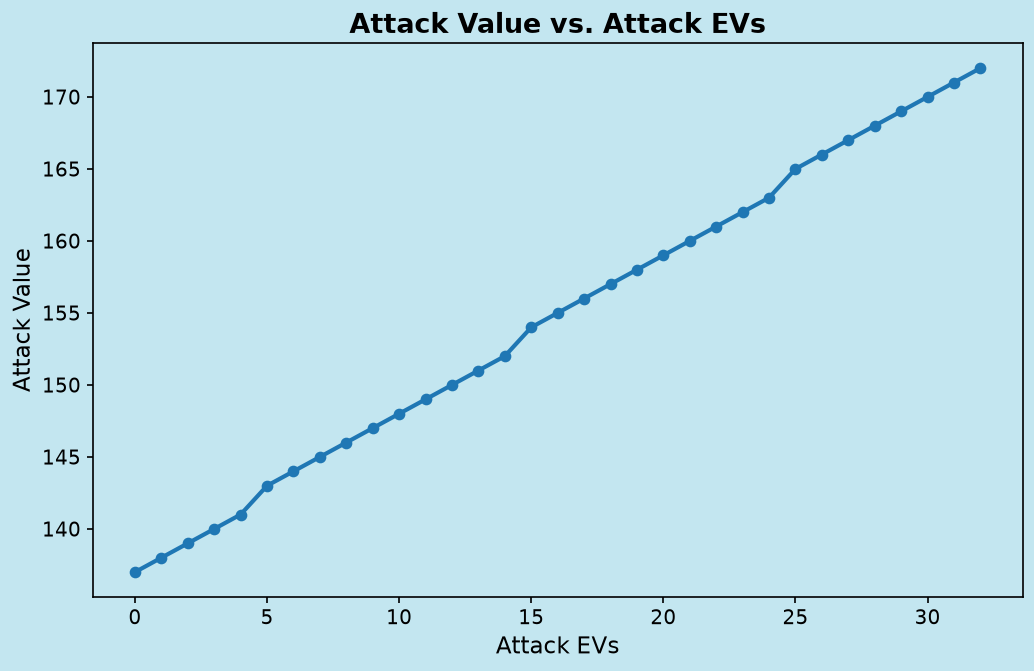

In [102]:
attack_evs_range = range(0, 33)
attack_values = [calc_attack(ev, base_attack=105, atk_mult=1.1) for ev in attack_evs_range]

plt.plot(attack_evs_range, attack_values, marker='o')
plt.title('Attack Value vs. Attack EVs')
plt.xlabel('Attack EVs')
plt.ylabel('Attack Value')

Text(0, 0.5, 'Attack Value')

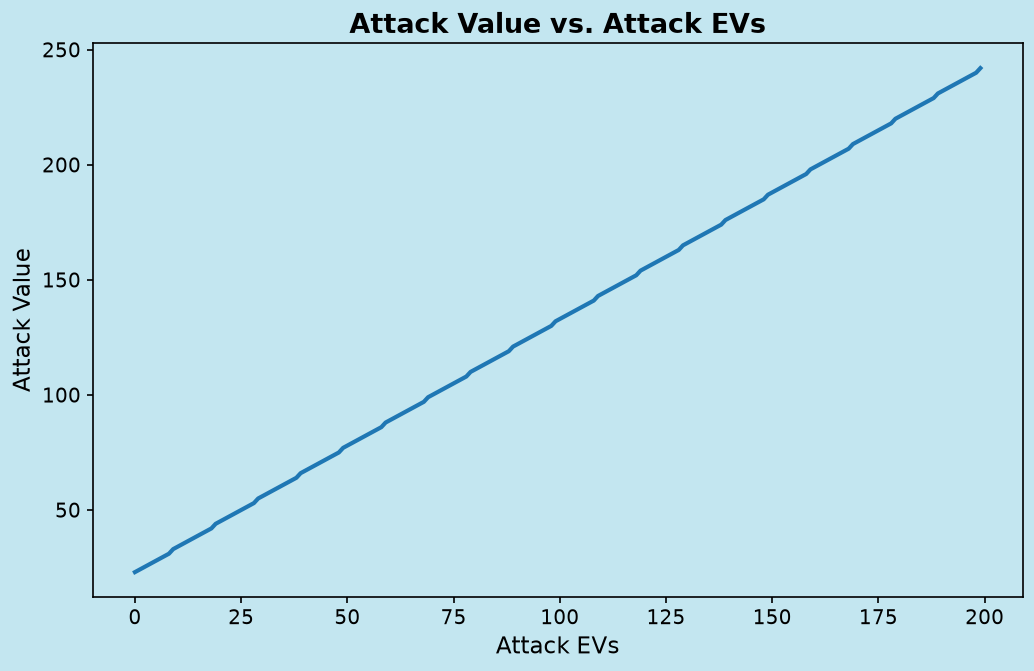

In [103]:
fake_attack_evs = range(0, 200)
attack_values = [calc_attack(ev, base_attack=1, atk_mult=1.1) for ev in fake_attack_evs]

plt.plot(fake_attack_evs, attack_values)
plt.title('Attack Value vs. Attack EVs')
plt.xlabel('Attack EVs')
plt.ylabel('Attack Value')

In [104]:
#find each attack ev pair that increases by more than 1 attack value
for i in range(len(attack_values) - 1):
    if attack_values[i + 1] - attack_values[i] > 1:
        print(f"Attack EVs: {fake_attack_evs[i]} -> {fake_attack_evs[i + 1]}, Attack Value: {attack_values[i]} -> {attack_values[i + 1]}")

TypeError: 'numpy.float64' object is not callable

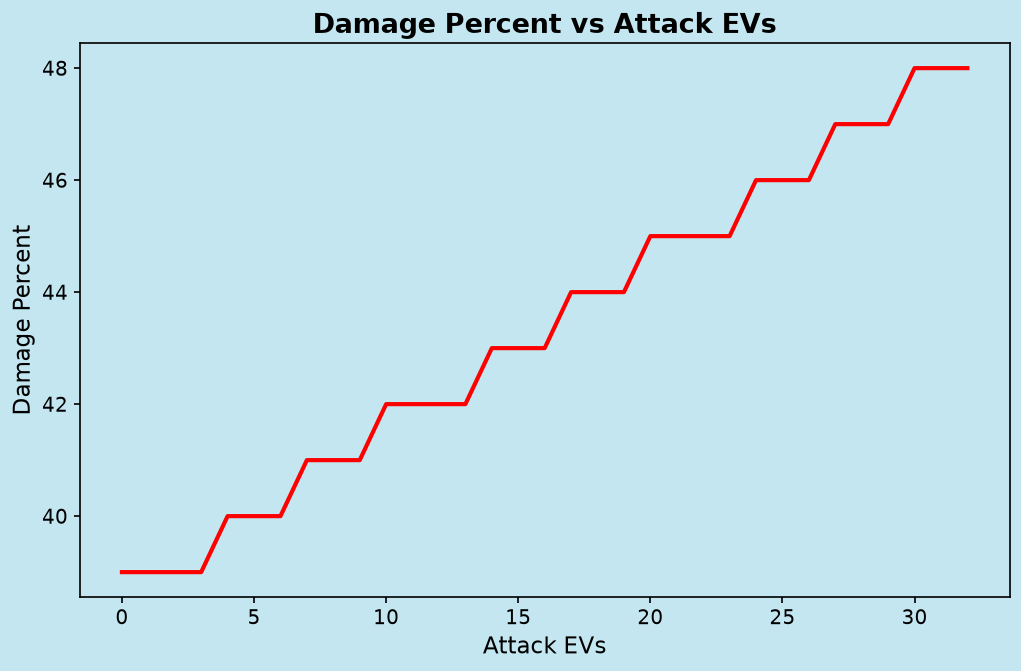

In [ ]:
# Fix health_evs and vary defense_evs
attack_evs_range = range(0, 33)
damage_percent_values = [damage_percent(attack_evs, base_attack=base_attack, power=100, total_evs=total_evs, defense=150, health=100, level=50, bonus=[1])[0] for attack_evs in attack_evs_range]

# Plot the curve
plt.plot(attack_evs_range, damage_percent_values, color='red')
plt.xlabel('Attack EVs')
plt.ylabel('Damage Percent')
plt.title(f'Damage Percent vs Attack EVs')
plt.show()

The amount of damage dealt can be shown as power * atk since this is how it shows up in the formula.

In [ ]:
%%manim -ql damagePowerFormula

class damagePowerFormula(Scene):
    def construct(self):
        eq1 = MathTex(r"damage = (\frac{(\frac{2 * Lvl}{5} + 2) * Power * \frac{Atk}{Def}}{50} + 2) * Extras")
        eq2 = MathTex(r"damage\% = \frac{(\frac{(\frac{2 * 50}{5} + 2) * Power * \frac{Atk}{Def}}{50} + 2) * Extras}{Health}")
        eq3 = MathTex(r"1 < \frac{(\frac{(\frac{2 * 50}{5} + 2) * Power * \frac{Atk}{Def}}{50} + 2) * Extras}{Health}")
        eq4 = MathTex(r"1 * Health < (\frac{(\frac{2 * 50}{5} + 2) * Power * \frac{Atk}{Def}}{50} + 2) * Extras")
        eq5 = MathTex(r"Health < (\frac{(\frac{2 * 50}{5} + 2) * Power *  Atk}{50 * Def} + 2) * Extras")
        eq6 = MathTex(r"Health < (\frac{(\frac{2 * 50}{5} + 2)}{50 * Def} * Power *  Atk + 2) * Extras")
        eq7 = MathTex(r"\frac{Health}{Extras} < \frac{22}{50 * Def} * Power *  Atk + 2")
        eq8 = MathTex(r"\frac{Health}{Extras} - 2 < \frac{22}{50 * Def} * Power *  Atk")
        eq9 = MathTex(r"(\frac{Health}{Extras} - 2)(\frac{50 * Def}{22}) < Power *  Atk")
        eq10 = MathTex(r"Power * Atk > (\frac{Health}{Extras} - 2)(\frac{25 * Def}{11})")




        # simpEQ = MathTex(r"damage \propto \frac{Power}{2} * \frac{Atk}{Def}")



        self.add(eq1)
        self.wait()
        self.play(TransformMatchingTex(eq1, eq2))
        self.wait()
        self.play(TransformMatchingTex(eq2, eq3))
        self.wait()
        self.play(TransformMatchingTex(eq3, eq4))
        self.wait()
        self.play(TransformMatchingTex(eq4, eq5))
        self.wait()
        self.play(TransformMatchingTex(eq5, eq6))
        self.wait()
        self.play(TransformMatchingTex(eq6, eq7))
        self.wait()
        self.play(TransformMatchingTex(eq7, eq8))
        self.wait()
        self.play(TransformMatchingTex(eq8, eq9))
        self.wait()
        self.play(TransformMatchingTex(eq9, eq10))
        self.wait()
        # self.play(TransformMatchingTex(eq5, simpEQ))
        # self.wait()

Manim Community v0.20.1

Using this new found formula we can calculate the Offence threshold

We know the damage roll is in extras and that can go as low as 0.8
For simplification we can ignore other extras for now

In [ ]:
def calc_bulk(health, defense, extras=[1]):
    # Calculate the minimum product of Power and Atk needed to exceed 100% damage
    min_power_atk_product = (health / (0.8 * extras[0]) - 2) * (25 * defense / 11)
                             #(25 * defense * ( 100 * health - 2)) / (0.8 * extras[0] * 11)
    return min_power_atk_product

In [ ]:
def calc_stats(pokemon, def_mult=1):
    # Calculate the actual health and defense stats based on base stats and EVs
    calculated_health = pokemon["base_health"] + pokemon['hp_evs'] + 75
    calculated_defense = math.floor((pokemon["base_defense"] + pokemon["def_evs"] + 20) * def_mult)
    calculated_special_defense = math.floor((pokemon["base_special_defense"] + pokemon["sp_def_evs"] + 20) * def_mult)

    
    return calculated_health, calculated_defense, calculated_special_defense

In [ ]:
pokemon = [
    {"name": "Charizard-Y", "base_health": 78, "base_defense": 78, "base_special_defense": 115, "extras": [1], "hp_evs": 0, "def_evs": 0, "sp_def_evs": 0},
    {"name": "Garchomp", "base_health": 108, "base_defense": 95, "base_special_defense": 85, "extras": [1], "hp_evs": 0, "def_evs": 0, "sp_def_evs": 0},
]

In [ ]:
b = []

for p in pokemon:
    hp, defense, sp_defense = calc_stats(p, def_mult=1)
    min_product = calc_bulk(hp, defense)
    print(f"{p['name']} requires Power * Atk > {min_product:.2f} to exceed 100% damage.")
    b.append(min_product)

    min_product = calc_bulk(hp, defense, [1.5])
    print(f"{p['name']} requires Power * Atk > {min_product:.2f} to exceed 100% damage with STAB.")
    b.append(min_product)


Charizard-Y requires Power * Atk > 42151.14 to exceed 100% damage.
Charizard-Y requires Power * Atk > 27952.27 to exceed 100% damage with STAB.
Garchomp requires Power * Atk > 59264.20 to exceed 100% damage.
Garchomp requires Power * Atk > 39335.23 to exceed 100% damage with STAB.


Since extras is stuck inside the equation that means things like stab is not a flat 1.5 bonus to Power * Atk

In [ ]:
print(b[1]/b[0])
print(b[3]/b[2])

0.6631439894319683
0.663726571113561


If we set extras to 1.5 for STAB, how does moving it to the other side effect the formula?

In [ ]:
%%manim -ql damagePowerStabFormula

class damagePowerStabFormula(Scene):
    def construct(self):
        eq1 = MathTex(r"Power * Atk > (\frac{Health}{Extras} - 2)(\frac{25 * Def}{11})")
        eq2 = MathTex(r"Power * Atk > (\frac{Health}{1.5} - 2)(\frac{25 * Def}{11})")
        eq3 = MathTex(r"Power * Atk > (\frac{Health}{1.5} - \frac{3}{1.5})(\frac{25 * Def}{11})")
        eq4 = MathTex(r"Power * Atk > \frac{1}{1.5}(Health - 3)(\frac{25 * Def}{11})")
        eq5 = MathTex(r"Power * Atk * 1.5 > (Health - 3)(\frac{25 * Def}{11})")
        eq6 = MathTex(r"Power * Atk * Extras > (Health - 2 * Extras)(\frac{25 * Def}{11})")




        self.add(eq1)
        self.wait()
        self.play(TransformMatchingTex(eq1, eq2))
        self.wait()
        self.play(TransformMatchingTex(eq2, eq3))
        self.wait()
        self.play(TransformMatchingTex(eq3, eq4))
        self.wait()
        self.play(TransformMatchingTex(eq4, eq5))
        self.wait()
        self.play(TransformMatchingTex(eq5, eq6))
        self.wait()

Manim Community v0.20.1

In [ ]:
pokemon_list = pd.read_csv(r"data\pokemon_champions.csv")

#if row in pokemon_list is missing any of the required columns, drop it
pokemon_list = pokemon_list.dropna(subset=["name", "hp", "defense", "sp_def"])


# quick checks
print(pokemon_list.shape)
print(pokemon_list.columns.tolist())
pokemon_list.head()

(260, 12)
['name', 'type1', 'type2', 'abilities', 'moves', 'hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'bst']


,name,type1,type2,abilities,moves,hp,attack,defense,sp_atk,sp_def,speed,bst
0,Venusaur,Grass,Poison,Overgrow|Chlorophyll,Acid Spray|Amnesia|Body Slam|Bulldoze|Bullet S...,80.0,82.0,83.0,100.0,100.0,80.0,525.0
1,Charizard,Fire,Flying,Blaze|Solar Power,Acrobatics|Aerial Ace|Air Cutter|Air Slash|Anc...,78.0,84.0,78.0,109.0,85.0,100.0,534.0
2,Blastoise,Water,NaN,Torrent|Rain Dish,Aqua Jet|Aqua Ring|Aqua Tail|Aura Sphere|Avala...,79.0,83.0,100.0,85.0,105.0,78.0,530.0
3,Beedrill,Bug,Poison,Swarm|Sniper,Acrobatics|Aerial Ace|Agility|Air Cutter|Assur...,65.0,90.0,40.0,45.0,80.0,75.0,395.0
4,Pidgeot,Normal,Flying,Keen Eye|Tangled Feet|Big Pecks,Aerial Ace|Agility|Air Slash|Attract|Brave Bir...,83.0,80.0,75.0,70.0,70.0,101.0,479.0


In [ ]:
megas_list = pd.read_csv(r"data\mega_evolutions.csv")

megas_list = megas_list.dropna(subset=["base_pokemon", "hp", "defense", "sp_def"])


print(megas_list.shape)
print(megas_list.columns.tolist())
megas_list.head()

(81, 12)
['base_pokemon', 'mega_name', 'type1', 'type2', 'ability', 'hp', 'attack', 'defense', 'sp_atk', 'sp_def', 'speed', 'bst']


,base_pokemon,mega_name,type1,type2,ability,hp,attack,defense,sp_atk,sp_def,speed,bst
0,Venusaur,Mega Venusaur,Grass,Poison,Thick Fat,80,100,123,122,120,80,625
1,Charizard,Mega Charizard X,Fire,Dragon,Tough Claws,78,130,111,130,85,100,634
2,Charizard,Mega Charizard Y,Fire,Flying,Drought,78,104,78,159,115,100,634
3,Blastoise,Mega Blastoise,Water,NaN,Mega Launcher,79,103,120,135,115,78,630
4,Beedrill,Mega Beedrill,Bug,Poison,Adaptability,65,150,40,15,80,145,495


In [ ]:
def row_to_pokemon(row):
    return {
        "name": row.get("mega_name",row.get("name")),
        "base_health": int(row.get("hp", 0)),
        "base_attack": int(row.get("attack", 0)),
        "base_defense": int(row.get("defense", 0)),
        "base_special_attack": int(row.get("sp_atk", 0)),
        "base_special_defense": int(row.get("sp_def", 0)),
        "base_speed": int(row.get("speed", 0)),
        "extras": "",
        "hp_evs": int(row.get("hp_evs", 0)),
        "def_evs": int(row.get("def_evs", 0)),
        "sp_def_evs": int(row.get("sp_def_evs", 0)),
        "mega": True if row.get("mega_name") else False
    }

pokemon = [row_to_pokemon(r) for _, r in pokemon_list.fillna("").to_dict(orient="index").items()]

mega_pokemon = [row_to_pokemon(r) for _, r in megas_list.fillna("").to_dict(orient="index").items()]

print(len(pokemon))
print(pokemon[:3])

print(len(mega_pokemon))
print(mega_pokemon[:3])

#add mega pokemon to the pokemon list
pokemon.extend(mega_pokemon)

print(len(pokemon))
print(pokemon[:3])

260
[{'name': 'Venusaur', 'base_health': 80, 'base_attack': 82, 'base_defense': 83, 'base_special_attack': 100, 'base_special_defense': 100, 'base_speed': 80, 'extras': '', 'hp_evs': 0, 'def_evs': 0, 'sp_def_evs': 0, 'mega': False}, {'name': 'Charizard', 'base_health': 78, 'base_attack': 84, 'base_defense': 78, 'base_special_attack': 109, 'base_special_defense': 85, 'base_speed': 100, 'extras': '', 'hp_evs': 0, 'def_evs': 0, 'sp_def_evs': 0, 'mega': False}, {'name': 'Blastoise', 'base_health': 79, 'base_attack': 83, 'base_defense': 100, 'base_special_attack': 85, 'base_special_defense': 105, 'base_speed': 78, 'extras': '', 'hp_evs': 0, 'def_evs': 0, 'sp_def_evs': 0, 'mega': False}]
81
[{'name': 'Mega Venusaur', 'base_health': 80, 'base_attack': 100, 'base_defense': 123, 'base_special_attack': 122, 'base_special_defense': 120, 'base_speed': 80, 'extras': '', 'hp_evs': 0, 'def_evs': 0, 'sp_def_evs': 0, 'mega': True}, {'name': 'Mega Charizard X', 'base_health': 78, 'base_attack': 130, 'ba

In [ ]:
#for each pokemon, calculate it's defense bulk and special defense bulk, and add it to the pokemon dictionary
for p in pokemon:
    hp, defense, sp_defense = calc_stats(p, def_mult=1)
    min_product = calc_bulk(hp, defense)
    p["defense_bulk"] = min_product

    min_product = calc_bulk(hp, sp_defense)
    p["special_defense_bulk"] = min_product

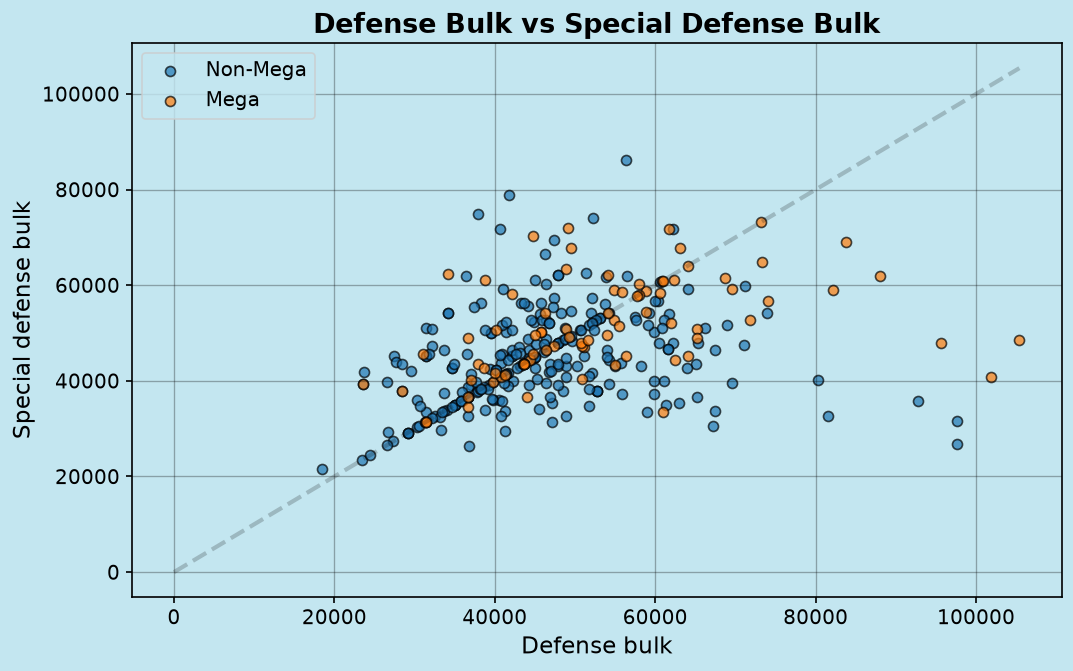

In [ ]:
#create scatterplot of defense bulk vs special defense bulk for each pokemon, with a line showing where they are equal

pokemon_df = pd.DataFrame(pokemon)
c = pokemon_df["mega"].astype(int)

plt.scatter(pokemon_df[pokemon_df["mega"]==False]["defense_bulk"], pokemon_df[pokemon_df["mega"]==False]["special_defense_bulk"], c='C0', alpha=0.7, edgecolor='k', label="Non-Mega")

plt.scatter(pokemon_df[pokemon_df["mega"]==True]["defense_bulk"], pokemon_df[pokemon_df["mega"]==True]["special_defense_bulk"], c='C1', alpha=0.7, edgecolor='k', label="Mega")

plt.xlabel("Defense bulk")
plt.ylabel("Special defense bulk")
plt.title("Defense Bulk vs Special Defense Bulk")
plt.grid(alpha=0.3)
plt.plot([0, max(pokemon_df["defense_bulk"].max(), pokemon_df["special_defense_bulk"].max())],
         [0, max(pokemon_df["defense_bulk"].max(), pokemon_df["special_defense_bulk"].max())],
         c='k', linestyle='--', alpha=0.2)
plt.legend()
plt.show()

In [ ]:
#print the top 5 pokemon with the highest defense bulk and the pokemon with the highest special defense bulk
top5_def = pokemon_df.sort_values(by="defense_bulk", ascending=False).head(5)
top5_spdef = pokemon_df.sort_values(by="special_defense_bulk", ascending=False).head(5)

print(top5_def[["name","defense_bulk"]])
print(top5_spdef[["name","special_defense_bulk"]])

              name   defense_bulk
282   Mega Steelix  105397.727273
294    Mega Aggron  101846.590909
181  Avalugg-Hisui   97595.454545
180        Avalugg   97595.454545
271   Mega Slowbro   95681.818182
             name  special_defense_bulk
38        Snorlax          86198.863636
172        Goodra          78914.772727
152       Florges          74839.772727
173  Goodra-Hisui          74085.227273
318   Mega Audino          73165.909091


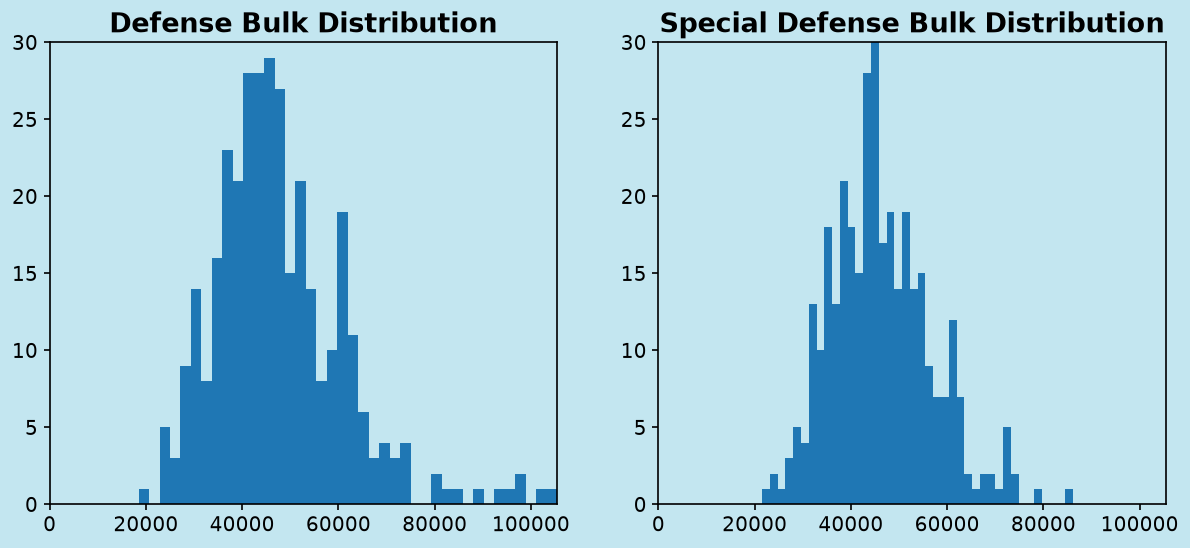

In [ ]:
len = max(pokemon_df["defense_bulk"].max(), pokemon_df["special_defense_bulk"].max())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))


ax1.hist(pokemon_df["defense_bulk"], bins=40, label="Defense Bulk")
ax1.set_xbound(0, len)
ax1.set_ybound(0,30)
ax1.title.set_text("Defense Bulk Distribution")

ax2.hist(pokemon_df["special_defense_bulk"], bins=40, label="Special Defense Bulk")
ax2.set_xbound(0, len)
ax2.set_ybound(0,30)
ax2.title.set_text("Special Defense Bulk Distribution")

plt.show()

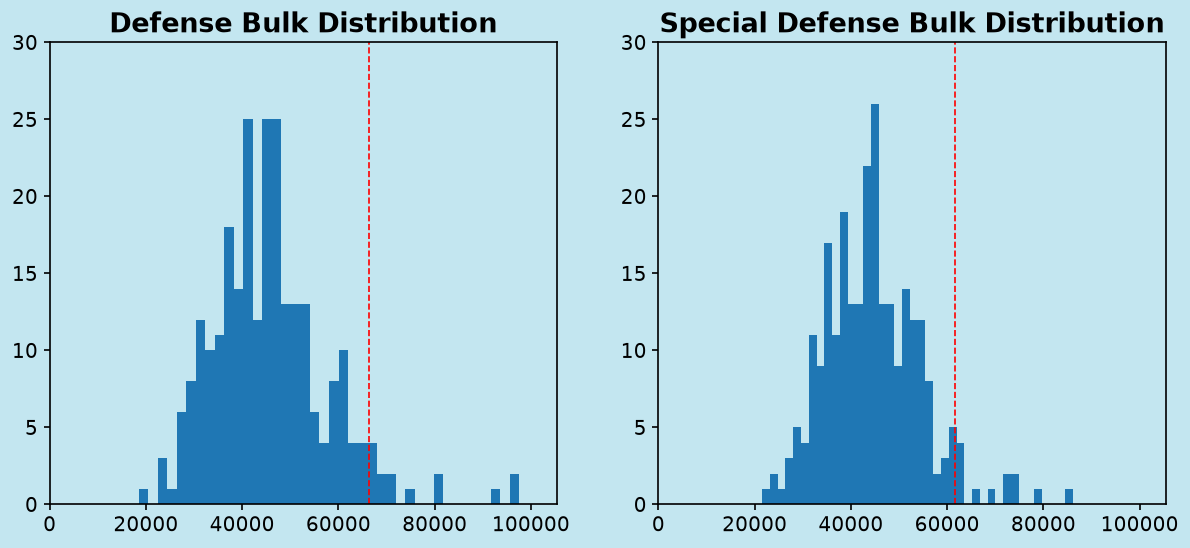

95th percentile of defense bulk for non-mega pokemon: 66303.8352272727
95th percentile of special defense bulk for non-mega pokemon: 61674.34659090908


In [ ]:
pokemon_df_no_megas = pokemon_df[pokemon_df["mega"] == False]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

defense_bulk_95 = pokemon_df_no_megas["defense_bulk"].quantile(0.95)
special_defense_bulk_95 = pokemon_df_no_megas["special_defense_bulk"].quantile(0.95)

ax1.hist(pokemon_df_no_megas["defense_bulk"], bins=40, label="Defense Bulk")
ax1.set_xbound(0, len)
ax1.set_ybound(0,30)
ax1.title.set_text("Defense Bulk Distribution")
ax1.axvline(defense_bulk_95, color='r', linestyle='dashed', linewidth=1, label='95th Percentile')

ax2.hist(pokemon_df_no_megas["special_defense_bulk"], bins=40, label="Special Defense Bulk")
ax2.set_xbound(0, len)
ax2.set_ybound(0,30)
ax2.title.set_text("Special Defense Bulk Distribution")
ax2.axvline(special_defense_bulk_95, color='r', linestyle='dashed', linewidth=1, label='95th Percentile')

plt.show()

print(f"95th percentile of defense bulk for non-mega pokemon: {defense_bulk_95}")
print(f"95th percentile of special defense bulk for non-mega pokemon: {special_defense_bulk_95}")

This is cool and all but in reality not very useful. Pokemon will have evs to survive certain hits and a lot of popular Pokemon have resistances to common types.

In [ ]:
attacks = {"name": "Sacred Sword", "power": 90*1.5*1.2, "base_atk": 125, "bonus": [1.5, 2], "PhySpec": "Physical", "atk_mult": 1.1}
defense = {"name": "Baxcalibur-Mega", "health": 222, "defense": 139, "special_defense": 121}

defense_value = defense["special_defense"] if attacks["PhySpec"] == "Special" else defense["defense"]


evs_map = np.zeros((33, 1))

for i in range(33):

    evs_map[i], _ = damage_percent(attack_evs=i, base_attack = attacks["base_atk"], power=attacks["power"], defense=defense_value, health=defense["health"], bonus=attacks["bonus"], atk_mult=attacks["atk_mult"])
    print(f"EVs map for {i} attack evs: {evs_map[i]}")

EVs map for 0 attack evs: [94.59459459]
EVs map for 1 attack evs: [95.4954955]
EVs map for 2 attack evs: [95.4954955]
EVs map for 3 attack evs: [97.2972973]
EVs map for 4 attack evs: [97.2972973]
EVs map for 5 attack evs: [98.1981982]
EVs map for 6 attack evs: [98.1981982]
EVs map for 7 attack evs: [98.1981982]
EVs map for 8 attack evs: [100.]
EVs map for 9 attack evs: [100.]
EVs map for 10 attack evs: [100.9009009]
EVs map for 11 attack evs: [100.9009009]
EVs map for 12 attack evs: [102.7027027]
EVs map for 13 attack evs: [102.7027027]
EVs map for 14 attack evs: [103.6036036]
EVs map for 15 attack evs: [105.40540541]
EVs map for 16 attack evs: [105.40540541]
EVs map for 17 attack evs: [106.30630631]
EVs map for 18 attack evs: [106.30630631]
EVs map for 19 attack evs: [106.30630631]
EVs map for 20 attack evs: [106.30630631]
EVs map for 21 attack evs: [108.10810811]
EVs map for 22 attack evs: [108.10810811]
EVs map for 23 attack evs: [109.00900901]
EVs map for 24 attack evs: [109.009009